In [1]:
# %% [1. GA IMPORTS]
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

sns.set_theme(style='whitegrid')


In [2]:
# %% [2. GA DATASET & SPLIT]
digits = load_digits(as_frame=True)
df = digits.frame
X = digits.data
y = digits.target

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"Train shape: {X_train.shape} | Test shape: {X_test.shape}")


Train shape: (1437, 64) | Test shape: (360, 64)


Shape: (1797, 65)
Null values: 0
Class counts:
 target
0    178
1    182
2    177
3    183
4    181
5    182
6    181
7    179
8    174
9    180
Name: count, dtype: int64


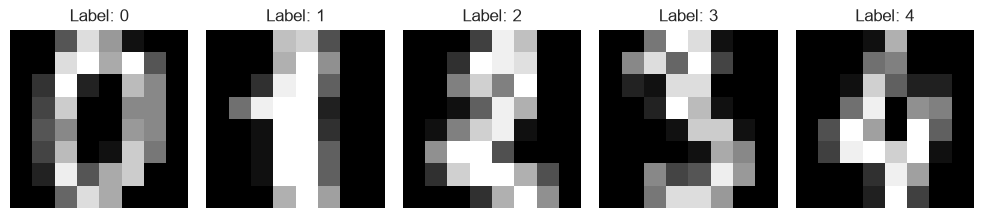

In [3]:
# %% [3. GA EXPLORATORY DATA ANALYSIS]
print("Shape:", df.shape)
print("Null values:", df.isnull().sum().sum())
print("Class counts:\n", y.value_counts().sort_index())

fig, axes = plt.subplots(1, 5, figsize=(10, 2.5))
for idx, ax in enumerate(axes):
    ax.imshow(digits.images[idx], cmap='gray')
    ax.set_title(f"Label: {digits.target[idx]}")
    ax.axis('off')
plt.tight_layout()
plt.show()


In [4]:
# %% [4. GA FEATURE SCALING]
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


In [5]:
# %% [5. GA MODEL - FEATURE SELECTION]
n_features = X_train_scaled.shape[1]
pop_size = 20
generations = 15
mut_rate = 0.05
rng = np.random.default_rng(42)

def fitness(chromosome):
    cols = np.where(chromosome == 1)[0]
    if len(cols) == 0:
        return 0.0
    clf = LogisticRegression(max_iter=300)
    clf.fit(X_train_scaled[:, cols], y_train)
    acc = accuracy_score(y_test, clf.predict(X_test_scaled[:, cols]))
    return acc - 0.001 * (len(cols) / n_features)

pop = rng.integers(0, 2, size=(pop_size, n_features))
best_scores = []

for gen in range(generations):
    scores = np.array([fitness(ind) for ind in pop])
    best_idx = int(np.argmax(scores))
    best_scores.append(scores[best_idx])
    best_ind = pop[best_idx].copy()

    parents = []
    for _ in range(pop_size):
        i, j = rng.choice(pop_size, 2, replace=False)
        parents.append(pop[i] if scores[i] > scores[j] else pop[j])
    parents = np.array(parents)

    next_pop = [best_ind]
    for i in range(1, pop_size):
        p1, p2 = parents[i], parents[(i + 1) % pop_size]
        pt = rng.integers(1, n_features)
        child = np.concatenate([p1[:pt], p2[pt:]])
        mut_mask = rng.random(n_features) < mut_rate
        child = np.where(mut_mask, 1 - child, child)
        next_pop.append(child)
    pop = np.array(next_pop)

selected = np.where(best_ind == 1)[0]
final_model = LogisticRegression(max_iter=300).fit(X_train_scaled[:, selected], y_train)
y_pred = final_model.predict(X_test_scaled[:, selected])


Selected Features: 37/64
Test Accuracy    : 0.9806

Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00        33
           1       1.00      1.00      1.00        28
           2       1.00      1.00      1.00        33
           3       1.00      0.97      0.99        34
           4       1.00      0.98      0.99        46
           5       0.96      0.96      0.96        47
           6       0.94      0.97      0.96        35
           7       1.00      0.97      0.99        34
           8       0.97      1.00      0.98        30
           9       0.95      0.97      0.96        40

    accuracy                           0.98       360
   macro avg       0.98      0.98      0.98       360
weighted avg       0.98      0.98      0.98       360



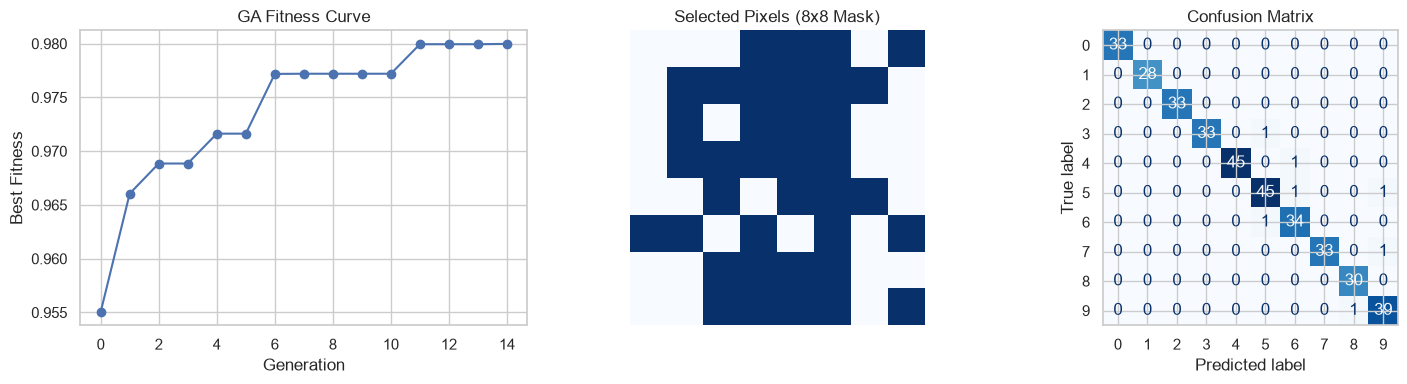

In [6]:
# %% [6. GA EVALUATION & VISUALIZATION]
print(f"Selected Features: {len(selected)}/{n_features}")
print(f"Test Accuracy    : {accuracy_score(y_test, y_pred):.4f}")
print("\nClassification Report:\n", classification_report(y_test, y_pred))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].plot(best_scores, marker='o')
axes[0].set_xlabel('Generation')
axes[0].set_ylabel('Best Fitness')
axes[0].set_title('GA Fitness Curve')

axes[1].imshow(best_ind.reshape(8, 8), cmap='Blues')
axes[1].set_title('Selected Pixels (8x8 Mask)')
axes[1].axis('off')

ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred)).plot(ax=axes[2], cmap='Blues', colorbar=False)
axes[2].set_title('Confusion Matrix')

plt.tight_layout()
plt.show()
